# Sequence-model exploration: treating each allocation's 20-day history as a proper time series

So far, all models have used the 20 lagged `RET_i` / `SIGNED_VOLUME_i` columns as flat, independent features fed to a tree-based model. This notebook tests a structurally different idea: feed the 20-day sequence *as a sequence* (in true lag order, 20 -> 1) into a small recurrent/1D-conv network, so the model can learn temporal patterns (e.g. streaks, decelerating momentum, volatility clustering) rather than treating each lag as an unrelated column.

This is a genuinely different modelling approach from everything tried before, not another feature added to LightGBM -- so expect more setup work and less certainty of a quick win. Uses the same TS-grouped CV philosophy as the rest of the project so results are comparable.

**Caveat to keep in mind throughout:** earlier analysis established that `TS` row order does *not* reflect true chronology across snapshots of the same allocation (the RET_i/RET_1 offset-correlation test came back ~0). That finding is about *ordering across rows* for a given allocation over calendar time. It does NOT affect the within-row lag sequence used here -- RET_20...RET_1 within a single row is still a genuine, correctly-ordered 20-day history ending at that row's snapshot. This notebook only uses within-row sequences, so it is not affected by that limitation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [2]:
X_train = pd.read_csv('../data/X_train.csv', index_col='ROW_ID')
X_test = pd.read_csv('../data/X_test.csv', index_col='ROW_ID')
y_train = pd.read_csv('../data/y_train.csv', index_col='ROW_ID')
sample_submission = pd.read_csv('../data/sample_submission.csv', index_col='ROW_ID')
total_data = pd.concat([X_train, y_train], axis=1)

print(X_train.shape, X_test.shape)

(527073, 44) (31870, 44)


## Build sequence arrays

Reorder lags from oldest -> newest (RET_20 ... RET_1) so the sequence reads naturally forward in time. Stack RET and SIGNED_VOLUME as two channels per timestep. Recall `SIGNED_VOLUME_1` is ~73.5% NaN (structural reporting-lag issue found earlier) -- fill NaNs with 0 and add an explicit missingness flag channel so the model can distinguish "no volume reported" from "volume was exactly zero".

In [3]:
def build_sequence_arrays(df):
    ret_cols = [f'RET_{i}' for i in range(20, 0, -1)]
    vol_cols = [f'SIGNED_VOLUME_{i}' for i in range(20, 0, -1)]

    ret_seq_raw = df[ret_cols].to_numpy(dtype=np.float32)
    vol_seq_raw = df[vol_cols].to_numpy(dtype=np.float32)

    ret_missing = np.isnan(ret_seq_raw).astype(np.float32)  # worth tracking, same reasoning as volume
    ret_seq = np.nan_to_num(ret_seq_raw, nan=0.0)

    vol_missing = np.isnan(vol_seq_raw).astype(np.float32)
    vol_seq = np.nan_to_num(vol_seq_raw, nan=0.0)

    ret_seq = ret_seq / (np.abs(ret_seq).std() + 1e-8)
    vol_seq = vol_seq / (np.abs(vol_seq).std() + 1e-8)

    seq = np.stack([ret_seq, vol_seq, vol_missing, ret_missing], axis=-1)  # now 4 channels
    return seq
print("Building sequence arrays for training data...")
X_train_seq_full = build_sequence_arrays(X_train)
print("Sequence array shape (rows, timesteps, channels):", X_train_seq_full.shape)
print("NaNs remaining:", np.isnan(X_train_seq_full).sum())

Building sequence arrays for training data...
Sequence array shape (rows, timesteps, channels): (527073, 20, 4)
NaNs remaining: 0


## Dataset / model definition

Start simple: a small GRU followed by a linear head, plus the two scalar features that have already proven useful (`MEDIAN_DAILY_TURNOVER`, `ALLOC_TARGET_ENCODING`) concatenated onto the GRU's final hidden state. This lets the sequence model add on top of what you already know works, rather than starting from zero.

In [4]:
class AllocationSequenceDataset(Dataset):
    def __init__(self, seq_array, scalar_array, labels):
        self.seq = torch.tensor(seq_array, dtype=torch.float32)
        self.scalar = torch.tensor(scalar_array, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.seq[idx], self.scalar[idx], self.labels[idx]


class SequenceModel(nn.Module):
    def __init__(self, n_channels=4, hidden_size=16, n_scalars=2):
        super().__init__()
        self.gru = nn.GRU(input_size=n_channels, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Sequential(
            nn.Linear(hidden_size + n_scalars, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 1),
        )

    def forward(self, seq, scalars):
        _, h_n = self.gru(seq)          # h_n: (1, batch, hidden_size)
        h = h_n.squeeze(0)              # (batch, hidden_size)
        combined = torch.cat([h, scalars], dim=1)
        return self.head(combined).squeeze(1)  # raw logits

## OOF allocation target encoding helper

Reused from the LightGBM notebooks -- same leakage-safe, fold-scoped logic. Kept as a standalone function here so this notebook is self-contained.

In [5]:
def compute_fold_alloc_encoding(allocations_train, targets_train, allocations_query):
    fold_df = pd.DataFrame({'ALLOCATION': allocations_train, 'target': targets_train})
    alloc_sign_rate = fold_df.groupby('ALLOCATION')['target'].apply(lambda s: (np.sign(s) > 0).mean())
    global_rate = (np.sign(targets_train) > 0).mean()
    return allocations_query.map(alloc_sign_rate).fillna(global_rate).to_numpy(dtype=np.float32)

## Training / evaluation loop (TS-grouped CV, same folds philosophy as the LightGBM notebooks)

Keep epochs and hidden size small at first -- the goal here is to establish whether a sequence model is *at all* competitive with the LightGBM baseline (52.33% +/- 0.26) before spending time tuning it. If it's meaningfully worse even after basic tuning, that's a useful negative result: it would suggest the 20-day sequence genuinely doesn't contain exploitable temporal structure beyond what flat lag features + allocation identity already capture.

Fold 1 - Accuracy: 52.46%
Fold 2 - Accuracy: 52.66%
Fold 3 - Accuracy: 52.15%
Fold 4 - Accuracy: 53.16%
Fold 5 - Accuracy: 52.26%
Fold 6 - Accuracy: 52.55%
Fold 7 - Accuracy: 51.99%
Fold 8 - Accuracy: 52.05%


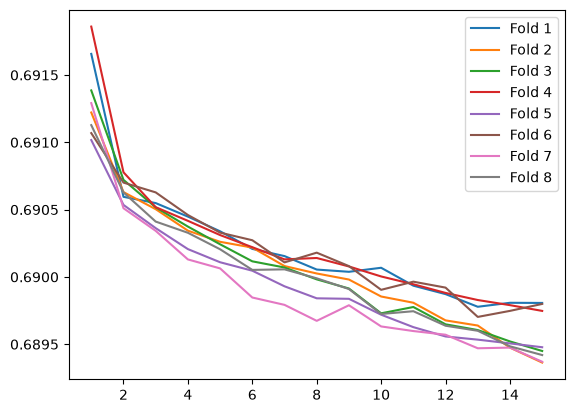

  Prediction stats: min=0.2791, max=0.7667, mean=0.5088
  Fraction predicted positive (>0.5): 0.6058
  True fraction positive: 0.5000

Sequence model accuracy: 52.41% (+- 0.36)
Compare against LightGBM RET_1 + turnover + ALLOC_TARGET_ENCODING: 52.47% (+- 0.26)


In [6]:
N_EPOCHS = 15
BATCH_SIZE = 2048
LR = 2e-3
N_SPLITS = 8

train_dates = X_train['TS'].unique()
scores_seq = []

splits = KFold(n_splits=N_SPLITS, random_state=0, shuffle=True).split(train_dates)

median_turnover_global = X_train['MEDIAN_DAILY_TURNOVER'].median()
fold_losses = []
for fold_i, (local_train_dates_ids, local_test_dates_ids) in enumerate(splits):
    local_train_dates = train_dates[local_train_dates_ids]
    local_test_dates = train_dates[local_test_dates_ids]

    local_train_ids = X_train['TS'].isin(local_train_dates)
    local_test_ids = X_train['TS'].isin(local_test_dates)

    # --- sequence arrays ---
    seq_train = X_train_seq_full[local_train_ids.to_numpy()]
    seq_test = X_train_seq_full[local_test_ids.to_numpy()]

    # --- scalar features: turnover (fillna) + OOF allocation encoding ---
    turnover_train = X_train.loc[local_train_ids, 'MEDIAN_DAILY_TURNOVER'].fillna(median_turnover_global).to_numpy(dtype=np.float32)
    turnover_test = X_train.loc[local_test_ids, 'MEDIAN_DAILY_TURNOVER'].fillna(median_turnover_global).to_numpy(dtype=np.float32)

    y_local_train_raw = y_train.loc[local_train_ids, 'target']
    y_local_test_raw = y_train.loc[local_test_ids, 'target']

    alloc_enc_train = compute_fold_alloc_encoding(
        X_train.loc[local_train_ids, 'ALLOCATION'], y_local_train_raw, X_train.loc[local_train_ids, 'ALLOCATION']
    )
    alloc_enc_test = compute_fold_alloc_encoding(
        X_train.loc[local_train_ids, 'ALLOCATION'], y_local_train_raw, X_train.loc[local_test_ids, 'ALLOCATION']
    )

    scalar_train = np.stack([turnover_train, alloc_enc_train], axis=1)
    scalar_test = np.stack([turnover_test, alloc_enc_test], axis=1)

    # standardize scalars using train-fold stats only
    scalar_mean = scalar_train.mean(axis=0)
    scalar_std = scalar_train.std(axis=0) + 1e-8
    scalar_train = (scalar_train - scalar_mean) / scalar_std
    scalar_test = (scalar_test - scalar_mean) / scalar_std

    labels_train = (y_local_train_raw > 0).astype(np.float32).to_numpy()
    labels_test = (y_local_test_raw > 0).astype(np.float32).to_numpy()

    train_ds = AllocationSequenceDataset(seq_train, scalar_train, labels_train)
    test_ds = AllocationSequenceDataset(seq_test, scalar_test, labels_test)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

    model = SequenceModel().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()

    model = SequenceModel().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()
    epoch_losses = []
    for epoch in range(N_EPOCHS):
        model.train()
        epoch_loss = 0.0
        n_batches = 0
        for seq_batch, scalar_batch, label_batch in train_loader:
            seq_batch, scalar_batch, label_batch = seq_batch.to(device), scalar_batch.to(device), label_batch.to(device)
            optimizer.zero_grad()
            logits = model(seq_batch, scalar_batch)
            loss = loss_fn(logits, label_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        #print(f"  Epoch {epoch+1}: avg loss = {epoch_loss / n_batches:.4f}")
        epoch_losses.append(epoch_loss / n_batches)
        

    model.eval()
    all_preds = []
    with torch.no_grad():
        for seq_batch, scalar_batch, _ in test_loader:
            seq_batch, scalar_batch = seq_batch.to(device), scalar_batch.to(device)
            logits = model(seq_batch, scalar_batch)
            probs = torch.sigmoid(logits).cpu().numpy()
            all_preds.append(probs)
    all_preds = np.concatenate(all_preds)
    #print(f"NaNs in turnover_train: {np.isnan(turnover_train).sum()}")
    #print(f"NaNs in alloc_enc_train: {np.isnan(alloc_enc_train).sum()}")
    #print(f"NaNs in scalar_train (pre-standardize): {np.isnan(scalar_train).sum()}")
    score = accuracy_score(labels_test, (all_preds > 0.5).astype(int))
    scores_seq.append(score)
    print(f"Fold {fold_i + 1} - Accuracy: {score * 100:.2f}%")
    fold_losses.append(epoch_losses)
for i, fold_loss in enumerate(fold_losses):
    plt.plot(np.arange(1, N_EPOCHS + 1), fold_loss, label=f'Fold {i + 1}')
plt.legend()   
plt.show()
mean = np.mean(scores_seq) * 100
std = np.std(scores_seq) * 100
print(f"  Prediction stats: min={all_preds.min():.4f}, max={all_preds.max():.4f}, mean={all_preds.mean():.4f}")
print(f"  Fraction predicted positive (>0.5): {(all_preds > 0.5).mean():.4f}")
print(f"  True fraction positive: {labels_test.mean():.4f}")
print(f"\nSequence model accuracy: {mean:.2f}% (+- {std:.2f})")
print("Compare against LightGBM RET_1 + turnover + ALLOC_TARGET_ENCODING: 52.47% (+- 0.26)")

In [7]:
# build the allocation encoding using the FULL training set (no fold-holding needed for the actual test set)
full_alloc_encoding = compute_fold_alloc_encoding(
    X_train['ALLOCATION'], y_train['target'], X_test['ALLOCATION']
)

test_turnover = X_test['MEDIAN_DAILY_TURNOVER'].fillna(median_turnover_global).to_numpy(dtype=np.float32)
test_alloc_enc = full_alloc_encoding

scalar_test = np.stack([test_turnover, test_alloc_enc], axis=1)

# standardize using the SAME mean/std computed from training data during the CV loop
# (scalar_mean, scalar_std must already exist from your training run -- reuse them, don't recompute)
scalar_test = (scalar_test - scalar_mean) / scalar_std

all_preds = []
test_loader = DataLoader(AllocationSequenceDataset(
    build_sequence_arrays(X_test),
    scalar_test,
    np.zeros(len(X_test), dtype=np.float32)  # dummy labels, unused for prediction
), batch_size=BATCH_SIZE, shuffle=False)

model.eval()
with torch.no_grad():
    for seq_batch, scalar_batch, label_batch in test_loader:
        seq_batch, scalar_batch = seq_batch.to(device), scalar_batch.to(device)
        logits = model(seq_batch, scalar_batch)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_preds.append(probs)

output_probs = np.concatenate(all_preds)
output_preds = (output_probs > 0.5).astype(int)
df_submission = pd.DataFrame({'target': output_preds}, index=X_test.index)
df_submission.to_csv('../outputs/sequence_model_submission.csv')

## Interpreting the result

- If the sequence model **meaningfully beats** 52.33%: the 20-day history contains temporal structure a flat lag representation misses (e.g. acceleration/deceleration patterns, volatility clustering) -- worth investing more time here (deeper model, attention, hyperparameter search).
- If it's **roughly the same**: the flat-lag + allocation-identity representation was already capturing what matters; the extra modelling complexity isn't buying anything, consistent with the RET_i correlation table showing almost all signal concentrated in RET_1 alone with the rest close to noise.
- If it's **notably worse**: likely needs more tuning (more epochs, different hidden size, learning rate schedule) before drawing conclusions -- neural sequence models are typically more hyperparameter-sensitive than LightGBM and may need more care to reach a fair comparison.

Whatever the outcome, this is a legitimate result to report: a genuinely different architecture was tried, not just another flat feature.